# Laboratorio #4 — Análisis Exploratorio de Datos (EDA)
**Universidad Técnica Nacional · ISW-911 Minería de Datos**

**Integrantes del grupo:**
- Krisley Castro Barrantes
- Kristel Ramírez
- Juan Daniel Ulate
- Marco López

**Conjunto de datos:** *Precios medios de electricidad* — Autoridad Reguladora de los Servicios Públicos (ARESEP), datos abiertos, enero 2025 a agosto 2026.

Cada fila es la facturación de **una empresa eléctrica**, en **una tarifa**, durante **un mes**: cantidad de abonados, energía vendida (kWh), ingresos (₡) y precio medio (₡/kWh), con y sin el Costo Variable de Generación (CVG).

## 0. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

---
# Parte 1 (puntos 2, 3, 4, 5 y 15)

## Puntos 2 y 3. Carga del conjunto de datos desde Git
El conjunto de datos de ARESEP viene en dos archivos (2025 y 2026) con las mismas columnas. Los dos se subieron sin modificar a la carpeta `data/` del repositorio público de GitHub del grupo y se leen directamente desde la URL *raw* de GitHub.

> Si GitHub no responde, el notebook usa la copia local de `data/` para poder seguir trabajando. **Para la entrega la lectura tiene que salir desde Git.**

In [2]:
# Repositorio público del grupo en GitHub
URL_BASE_GIT = "https://raw.githubusercontent.com/Sweetkriiz/Laboratorio4-main/main/data/"

ARCHIVOS = [
    "Datos_Abiertos_ARESEP_Precios_medios_2025.csv",
    "Datos_Abiertos_ARESEP_Precios_medios_2026.csv",
]

def leer_csv_git(nombre_archivo):
    """Lee un CSV desde el repositorio de GitHub; si falla, usa la copia local en data/."""
    try:
        datos = pd.read_csv(URL_BASE_GIT + nombre_archivo, encoding="utf-8")
        print(f"Leído desde GitHub: {nombre_archivo}")
    except Exception as error:
        datos = pd.read_csv("data/" + nombre_archivo, encoding="utf-8")
        print(f"GitHub no disponible ({type(error).__name__}); leído desde la copia local: {nombre_archivo}")
    return datos

df = pd.concat([leer_csv_git(archivo) for archivo in ARCHIVOS], ignore_index=True)
print("Filas y columnas del conjunto unido:", df.shape)

Leído desde GitHub: Datos_Abiertos_ARESEP_Precios_medios_2025.csv
Leído desde GitHub: Datos_Abiertos_ARESEP_Precios_medios_2026.csv
Filas y columnas del conjunto unido: (1472, 13)


## Punto 4. Funciones básicas para ver las características del conjunto de datos

### 4.1 Primeras y últimas filas

In [3]:
df.head(10)

,Mes,Año,Empresa,Tarifa,Abonados,Ventas,Ingreso sin CVG,Ingreso con CVG,Precio Medio sin CVG,Precio Medio con CVG,Trimestre,Sistema,Trimestral
0,Diciembre,2025,CNFL,Alumbrado Público,0,"5,221,777.24","192,784,383.98","192,784,383.98",36.92,36.92,IV Trimestre,Distribucion,2025 4
1,Diciembre,2025,COOPESANTOS,Residencial,49685,"7,043,995.00","579,458,200.00","641,552,600.00",82.26,91.08,IV Trimestre,Distribucion,2025 4
2,Diciembre,2025,COOPELESCA,Residencial,108073,"19,937,840.00","1,546,824,000.00","1,633,719,000.00",77.58,81.94,IV Trimestre,Distribucion,2025 4
3,Diciembre,2025,COOPEGUANACASTE,Residencial,82147,"26,467,370.00","1,863,072,000.00","2,180,751,000.00",70.39,82.39,IV Trimestre,Distribucion,2025 4
4,Diciembre,2025,COOPEALFARORUIZ,Residencial,6356,"1,543,944.00","83,966,910.00","106,147,200.00",54.38,68.75,IV Trimestre,Distribucion,2025 4
5,Diciembre,2025,CNFL,Residencial,539680,"130,242,900.00","8,301,342,000.00","10,632,540,000.00",63.74,81.64,IV Trimestre,Distribucion,2025 4
6,Diciembre,2025,TOTAL NACIONAL,Promocional,30,"539,153.00","36,758,295.00","47,081,765.00",68.18,87.33,IV Trimestre,Distribucion,2025 4
7,Diciembre,2025,ESPH,Residencial,85454,"22,693,980.00","1,535,907,000.00","1,861,652,000.00",67.68,82.03,IV Trimestre,Distribucion,2025 4
8,Diciembre,2025,CNFL,Promocional,30,"539,153.00","36,758,295.00","47,081,765.00",68.18,87.33,IV Trimestre,Distribucion,2025 4
9,Diciembre,2025,JASEC,Preferencial,688,"884,066.00","43,117,180.00","53,931,760.00",48.77,61.00,IV Trimestre,Distribucion,2025 4


In [4]:
df.tail(5)

,Mes,Año,Empresa,Tarifa,Abonados,Ventas,Ingreso sin CVG,Ingreso con CVG,Precio Medio sin CVG,Precio Medio con CVG,Trimestre,Sistema,Trimestral
1467,Enero,2026,COOPESANTOS,Industrial,199,"283,396.17","45,076,160.00","44,279,380.00",159.06,156.25,I Trimestre,Distribucion,2026 1
1468,Enero,2026,COOPELESCA,Industrial,1671,"4,007,982.07","371,932,500.00","378,030,000.00",92.80,94.32,I Trimestre,Distribucion,2026 1
1469,Enero,2026,COOPEGUANACASTE,Industrial,231,"1,341,862.71","125,578,272.00","139,582,377.00",93.59,104.02,I Trimestre,Distribucion,2026 1
1470,Enero,2026,CNFL,Industrial,1354,"4,582,995.00","465,948,420.00","531,556,600.00",101.67,115.98,I Trimestre,Distribucion,2026 1
1471,Enero,2026,TOTAL NACIONAL,Ventas al servicio de Distribución,0,"116,932,677.00","4,754,417,406.91","4,524,353,066.38",40.66,38.69,I Trimestre,Generacion,2026 1


### 4.2 Tamaño, columnas y tipos de datos

In [5]:
print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])
print("\nColumnas:", list(df.columns))
print("\nTipos de datos:")
print(df.dtypes)

Cantidad de filas: 1472
Cantidad de columnas: 13

Columnas: ['Mes', 'Año', 'Empresa', 'Tarifa', 'Abonados', 'Ventas', 'Ingreso sin CVG', 'Ingreso con CVG', 'Precio Medio sin CVG', 'Precio Medio con CVG', 'Trimestre', 'Sistema', 'Trimestral']

Tipos de datos:
Mes                         str
Año                       int64
Empresa                     str
Tarifa                      str
Abonados                  int64
Ventas                  float64
Ingreso sin CVG         float64
Ingreso con CVG         float64
Precio Medio sin CVG    float64
Precio Medio con CVG    float64
Trimestre                   str
Sistema                     str
Trimestral                  str
dtype: object


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1472 entries, 0 to 1471
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Mes                   1472 non-null   str    
 1   Año                   1472 non-null   int64  
 2   Empresa               1472 non-null   str    
 3   Tarifa                1472 non-null   str    
 4   Abonados              1472 non-null   int64  
 5   Ventas                1472 non-null   float64
 6   Ingreso sin CVG       1472 non-null   float64
 7   Ingreso con CVG       1472 non-null   float64
 8   Precio Medio sin CVG  1472 non-null   float64
 9   Precio Medio con CVG  1472 non-null   float64
 10  Trimestre             1472 non-null   str    
 11  Sistema               1472 non-null   str    
 12  Trimestral            1472 non-null   str    
dtypes: float64(5), int64(2), str(6)
memory usage: 149.6 KB


### 4.3 Estadísticas descriptivas de las variables numéricas

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Año,"1,472.00","2,025.40",0.49,"2,025.00","2,025.00","2,025.00","2,026.00","2,026.00"
Abonados,"1,472.00","55,917.96","231,847.30",0.00,0.00,221.50,"7,298.50","1,790,412.00"
Ventas,"1,472.00","50,915,257.94","119,047,459.53",0.00,"964,452.50","8,314,585.00","30,764,530.06","833,571,960.58"
Ingreso sin CVG,"1,472.00","2,734,801,683.28","5,753,772,423.02","-115,904,929.23","57,625,415.00","568,918,550.00","1,766,096,182.50","33,530,904,080.00"
Ingreso con CVG,"1,472.00","3,219,984,503.47","6,780,650,483.82",45.02,"67,230,900.12","619,034,399.02","2,023,926,083.10","36,205,987,336.47"
Precio Medio sin CVG,"1,472.00","172,287.71","3,852,414.21",-236.77,49.26,64.68,81.96,"124,181,785.01"
Precio Medio con CVG,"1,472.00","168,912.05","3,655,600.32",0.00,54.05,72.66,87.13,"116,269,992.45"


### 4.4 Resumen de las variables categóricas (texto)

In [8]:
df.describe(exclude='number').T

,count,unique,top,freq
Mes,1472,12,Agosto,148
Empresa,1472,10,TOTAL NACIONAL,236
Tarifa,1472,13,Alumbrado Público,180
Trimestre,1472,4,II Trimestre,442
Sistema,1472,2,Distribucion,1252
Trimestral,1472,7,2025 4,222


In [9]:
# Cantidad de valores distintos por columna
df.nunique().sort_values()

Año                        2
Sistema                    2
Trimestre                  4
Trimestral                 7
Empresa                   10
Mes                       12
Tarifa                    13
Abonados                 684
Precio Medio con CVG    1161
Precio Medio sin CVG    1178
Ventas                  1380
Ingreso sin CVG         1390
Ingreso con CVG         1390
dtype: int64

In [10]:
# Frecuencias de las principales variables categóricas
for columna in ["Empresa", "Tarifa", "Sistema", "Trimestre"]:
    print(f"--- {columna} ---")
    print(df[columna].value_counts(), "\n")

--- Empresa ---
Empresa
TOTAL NACIONAL       236
CNFL                 200
ESPH                 180
ICE                  180
JASEC                160
COOPELESCA           156
COOPESANTOS          140
COOPEGUANACASTE      100
COOPEALFARORUIZ      100
Usuarios Directos     20
Name: count, dtype: int64 

--- Tarifa ---
Tarifa
Alumbrado Público                        180
Residencial                              180
Comercios y servicios                    180
Industrial                               180
Ventas al servicio de Distribución       140
Media tensión a                          140
Preferencial                             120
Media tensión b                          120
Residencial horaria                       80
Ventas a ICE distribución y a la CNFL     60
Promocional                               40
Residencial modalidad prepago             32
Usuarios Directos                         20
Name: count, dtype: int64 

--- Sistema ---
Sistema
Distribucion    1252
Generacion       2

In [11]:
print("Filas duplicadas:", df.duplicated().sum())
print("Memoria usada: {:.1f} KB".format(df.memory_usage(deep=True).sum() / 1024))

Filas duplicadas: 0
Memoria usada: 623.0 KB


### 4.5 Vista gráfica rápida

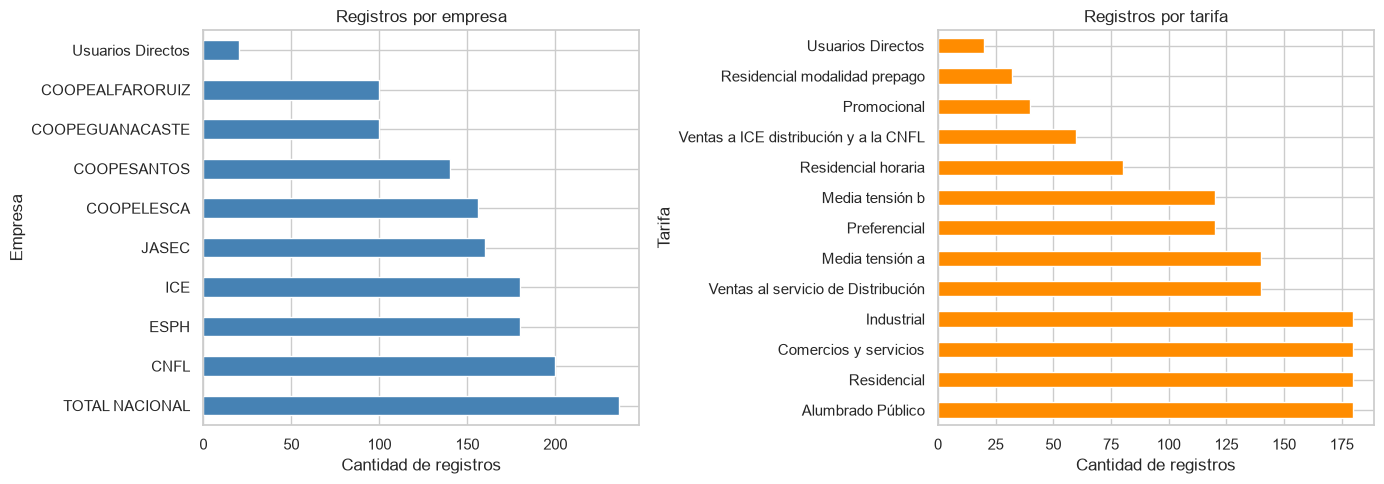

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
df["Empresa"].value_counts().plot(kind="barh", ax=ejes[0], color="steelblue")
ejes[0].set_title("Registros por empresa")
ejes[0].set_xlabel("Cantidad de registros")
df["Tarifa"].value_counts().plot(kind="barh", ax=ejes[1], color="darkorange")
ejes[1].set_title("Registros por tarifa")
ejes[1].set_xlabel("Cantidad de registros")
plt.tight_layout()
plt.show()

**Observaciones:**
- El conjunto tiene 1 472 filas y 13 columnas: 7 numéricas y 6 de texto.
- Hay 10 "empresas", pero una de ellas es **TOTAL NACIONAL**. No es una empresa, es la suma de las demás, así que sus filas repiten información (se revisa en valores atípicos).
- `Sistema` separa la **Distribución** (venta al cliente final) de la **Generación** (venta entre empresas).
- La columna `Mes` trae espacios en blanco al final (`"Julio     "`), lo cual hay que limpiar.

## Punto 5. Cambio de nombres de las columnas a español
Los nombres originales mezclan mayúsculas, espacios, tildes, la letra ñ (`Año`) y siglas (`CVG`). Se cambian a nombres en español **descriptivos**, en minúscula, sin espacios ni tildes, y con la unidad cuando aplica. Así son más fáciles de usar en código.

In [13]:
nombres_columnas = {
    "Mes": "mes",
    "Año": "anio",
    "Empresa": "empresa",
    "Tarifa": "tarifa",
    "Abonados": "cantidad_abonados",
    "Ventas": "ventas_kwh",
    "Ingreso sin CVG": "ingreso_sin_cvg_colones",
    "Ingreso con CVG": "ingreso_con_cvg_colones",
    "Precio Medio sin CVG": "precio_medio_sin_cvg",
    "Precio Medio con CVG": "precio_medio_con_cvg",
    "Trimestre": "trimestre",
    "Sistema": "sistema",
    "Trimestral": "periodo_trimestral",
}
df = df.rename(columns=nombres_columnas)
df.columns.tolist()

['mes',
 'anio',
 'empresa',
 'tarifa',
 'cantidad_abonados',
 'ventas_kwh',
 'ingreso_sin_cvg_colones',
 'ingreso_con_cvg_colones',
 'precio_medio_sin_cvg',
 'precio_medio_con_cvg',
 'trimestre',
 'sistema',
 'periodo_trimestral']

| Columna nueva | Significado |
|---|---|
| `mes`, `anio` | Mes y año del registro |
| `empresa` | Empresa eléctrica (ICE, CNFL, JASEC, ESPH, cooperativas…) |
| `tarifa` | Tipo de tarifa (residencial, preferencial, alumbrado público…) |
| `cantidad_abonados` | Número de clientes (abonados) en esa tarifa |
| `ventas_kwh` | Energía vendida en el mes (kWh) |
| `ingreso_sin_cvg_colones` / `ingreso_con_cvg_colones` | Ingreso facturado (₡) sin / con el Costo Variable de Generación |
| `precio_medio_sin_cvg` / `precio_medio_con_cvg` | Precio medio (₡/kWh) = ingreso ÷ ventas |
| `trimestre`, `periodo_trimestral` | Trimestre del año |
| `sistema` | Distribución o Generación |

---
# Parte 2 (puntos 6, 7 y 9)

## Punto 6. Valores nulos
### 6.1 Nulos explícitos (`NaN`)

In [14]:
nulos = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "porcentaje": (df.isnull().mean() * 100).round(2),
})
nulos

,nulos,porcentaje
mes,0,0.00
anio,0,0.00
empresa,0,0.00
tarifa,0,0.00
cantidad_abonados,0,0.00
ventas_kwh,0,0.00
ingreso_sin_cvg_colones,0,0.00
ingreso_con_cvg_colones,0,0.00
precio_medio_sin_cvg,0,0.00
precio_medio_con_cvg,0,0.00


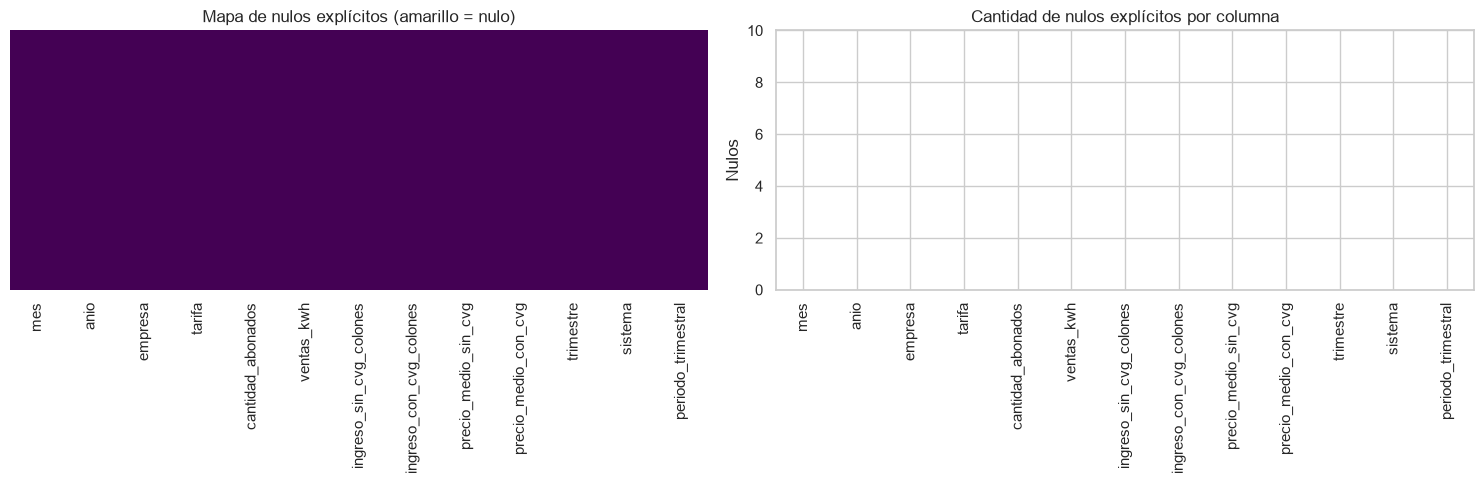

In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=ejes[0])
ejes[0].set_title("Mapa de nulos explícitos (amarillo = nulo)")
nulos["nulos"].plot(kind="bar", ax=ejes[1], color="steelblue")
ejes[1].set_title("Cantidad de nulos explícitos por columna")
ejes[1].set_ylabel("Nulos")
ejes[1].set_ylim(0, max(10, nulos["nulos"].max() + 5))
plt.tight_layout()
plt.show()

El archivo **no trae ningún `NaN`**: el mapa sale de un solo color y las barras quedan en cero. Pero eso no garantiza que todos los datos estén completos. Hay que buscar **nulos disfrazados**: textos vacíos o con solo espacios, y ceros que en realidad significan "no hay dato".

### 6.2 Nulos ocultos

In [16]:
columnas_texto = df.select_dtypes(exclude="number").columns
textos_vacios = {c: int((df[c].astype(str).str.strip() == "").sum()) for c in columnas_texto}
print("Textos vacíos o con solo espacios:", textos_vacios)

columnas_numericas = df.select_dtypes(include="number").columns
ceros = (df[columnas_numericas] == 0).sum()
print("\nCeros por columna numérica:")
print(ceros)

Textos vacíos o con solo espacios: {'mes': 0, 'empresa': 0, 'tarifa': 0, 'trimestre': 0, 'sistema': 0, 'periodo_trimestral': 0}

Ceros por columna numérica:
anio                         0
cantidad_abonados          380
ventas_kwh                   4
ingreso_sin_cvg_colones      0
ingreso_con_cvg_colones      0
precio_medio_sin_cvg         4
precio_medio_con_cvg         4
dtype: int64


In [17]:
# ¿Dónde aparecen los ceros?
print("Tarifas con cantidad_abonados = 0:")
print(df.loc[df["cantidad_abonados"] == 0, "tarifa"].value_counts(), "\n")
print("Registros con ventas_kwh = 0 o 1 kWh:")
df.loc[df["ventas_kwh"].isin([0, 1]), ["mes", "anio", "empresa", "tarifa", "ventas_kwh",
                                "ingreso_sin_cvg_colones", "precio_medio_sin_cvg", "precio_medio_con_cvg"]]

Tarifas con cantidad_abonados = 0:
tarifa
Alumbrado Público                        180
Ventas al servicio de Distribución       140
Ventas a ICE distribución y a la CNFL     60
Name: count, dtype: int64 

Registros con ventas_kwh = 0 o 1 kWh:


,mes,anio,empresa,tarifa,ventas_kwh,ingreso_sin_cvg_colones,precio_medio_sin_cvg,precio_medio_con_cvg
95,Noviembre,2025,COOPELESCA,Ventas al servicio de Distribución,1.00,"14,643,434.36","14,643,434.36","24,542,350.52"
465,Junio,2025,COOPELESCA,Ventas al servicio de Distribución,0.00,"34,410,488.08",0.00,0.00
901,Agosto,2026,COOPELESCA,Ventas al servicio de Distribución,1.00,"75,462,659.46","75,462,659.46","71,520,109.07"
903,Agosto,2026,COOPEALFARORUIZ,Ventas al servicio de Distribución,1.00,"11,154,342.49","11,154,342.49","10,287,647.49"
975,Julio,2026,COOPELESCA,Ventas al servicio de Distribución,1.00,"124,181,785.01","124,181,785.01","116,269,992.45"
977,Julio,2026,COOPEALFARORUIZ,Ventas al servicio de Distribución,1.00,"5,950,096.62","5,950,096.62","5,487,772.74"
1107,Mayo,2026,COOPEALFARORUIZ,Ventas al servicio de Distribución,1.00,"19,439,110.46","19,439,110.46","17,928,687.07"
1199,Abril,2026,COOPEALFARORUIZ,Ventas al servicio de Distribución,1.00,"2,661,446.54","2,661,446.54","2,454,655.49"
1344,Febrero,2026,COOPESANTOS,Ventas al servicio de Distribución,0.00,"44,273,212.23",0.00,0.00
1345,Febrero,2026,COOPELESCA,Ventas al servicio de Distribución,0.00,"-115,904,929.23",0.00,0.00


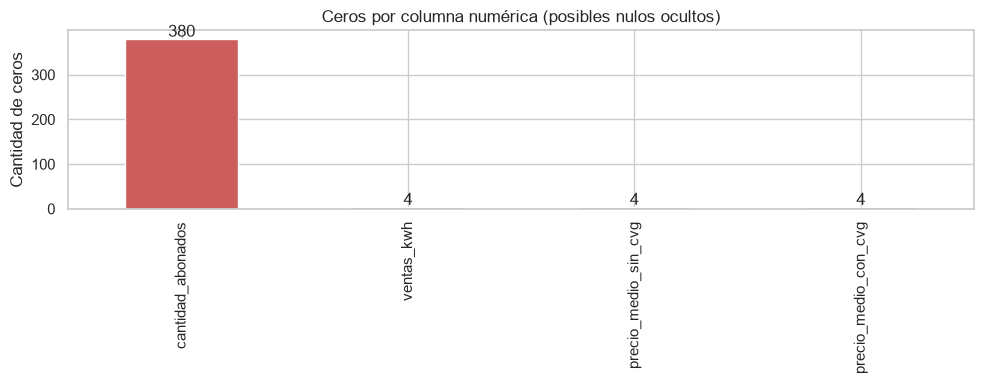

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
ceros[ceros > 0].plot(kind="bar", ax=ax, color="indianred")
ax.set_title("Ceros por columna numérica (posibles nulos ocultos)")
ax.set_ylabel("Cantidad de ceros")
for i, v in enumerate(ceros[ceros > 0]):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout()
plt.show()

**Hallazgos:**
1. **`cantidad_abonados = 0` (380 filas)** aparece solo en *Alumbrado Público* y en las ventas entre empresas de *Generación*. En esas tarifas no hay clientes individuales, así que el cero es un **valor real ("no aplica")** y **no se trata como nulo**.
2. **`ventas_kwh = 0` (4 filas) y `ventas_kwh = 1` (7 filas)**, todas de cooperativas (COOPELESCA, COOPESANTOS, COOPEALFARORUIZ) en *Ventas al servicio de Distribución*, con ingresos de millones de colones. Vender 0 o 1 kWh en un mes con esos ingresos no tiene sentido: son **valores de relleno** que se usaron cuando no había dato. Como el precio medio es ingreso ÷ ventas, en esas filas sale 0 o igual al ingreso completo. Son **datos faltantes disfrazados**.
3. No hay textos vacíos, pero `mes` trae espacios al final. Eso se corrige en el punto 9.

**Acción:** en esas 11 filas se ponen como `NaN` las ventas y los dos precios medios, para que quede claro que faltan. La imputación le corresponde al punto 8.

Nulos después de marcar los nulos ocultos:
ventas_kwh              11
precio_medio_sin_cvg    11
precio_medio_con_cvg    11
dtype: int64


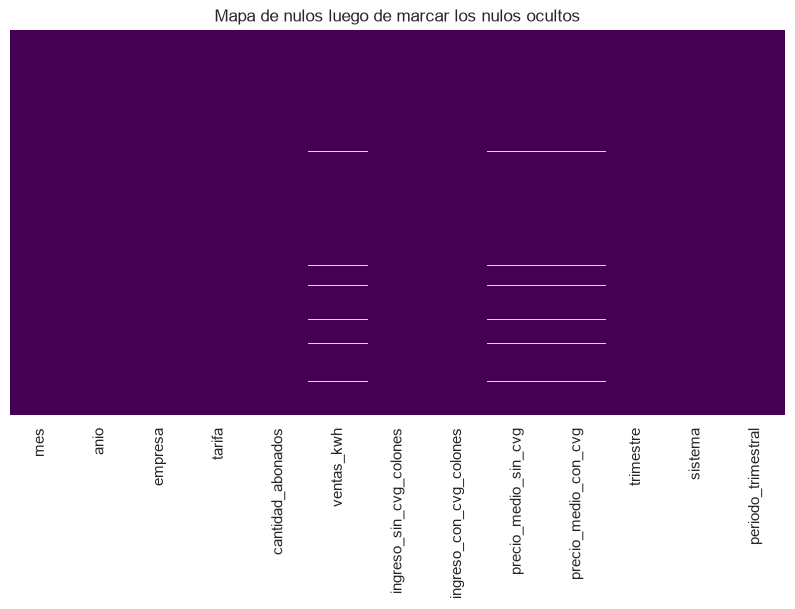

In [19]:
filas_sin_ventas = df["ventas_kwh"].isin([0, 1])
df.loc[filas_sin_ventas, ["ventas_kwh", "precio_medio_sin_cvg", "precio_medio_con_cvg"]] = np.nan
print("Nulos después de marcar los nulos ocultos:")
print(df.isnull().sum()[df.isnull().sum() > 0])

sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Mapa de nulos luego de marcar los nulos ocultos")
plt.show()

## Punto 7. Valores atípicos
Se usa el **método del rango intercuartílico (IQR)**: un valor es atípico si queda por debajo de `Q1 − 1.5·IQR` o por encima de `Q3 + 1.5·IQR`.

In [20]:
variables_continuas = ["cantidad_abonados", "ventas_kwh", "ingreso_sin_cvg_colones",
                       "ingreso_con_cvg_colones", "precio_medio_sin_cvg", "precio_medio_con_cvg"]

def resumen_atipicos_iqr(datos, columnas):
    """Devuelve límites IQR y cantidad de atípicos por columna."""
    filas = []
    for c in columnas:
        q1, q3 = datos[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        atipicos = ((datos[c] < lim_inf) | (datos[c] > lim_sup)).sum()
        filas.append({"variable": c, "Q1": q1, "Q3": q3, "limite_inferior": lim_inf,
                      "limite_superior": lim_sup, "atipicos": atipicos,
                      "porcentaje": round(atipicos / datos[c].notna().sum() * 100, 2)})
    return pd.DataFrame(filas).set_index("variable")

resumen_atipicos_iqr(df, variables_continuas)

,Q1,Q3,limite_inferior,limite_superior,atipicos,porcentaje
variable,,,,,,
cantidad_abonados,0.00,"7,298.50","-10,947.75","18,246.25",240,16.30
ventas_kwh,"1,016,725.00","30,827,575.72","-43,699,551.08","75,543,851.80",246,16.84
ingreso_sin_cvg_colones,"57,625,415.00","1,766,096,182.50","-2,505,080,736.25","4,328,802,333.75",230,15.62
ingreso_con_cvg_colones,"67,230,900.12","2,023,926,083.10","-2,867,811,874.36","4,958,968,857.58",233,15.83
precio_medio_sin_cvg,49.26,81.23,1.30,129.19,50,3.42
precio_medio_con_cvg,54.05,86.86,4.83,136.07,52,3.56


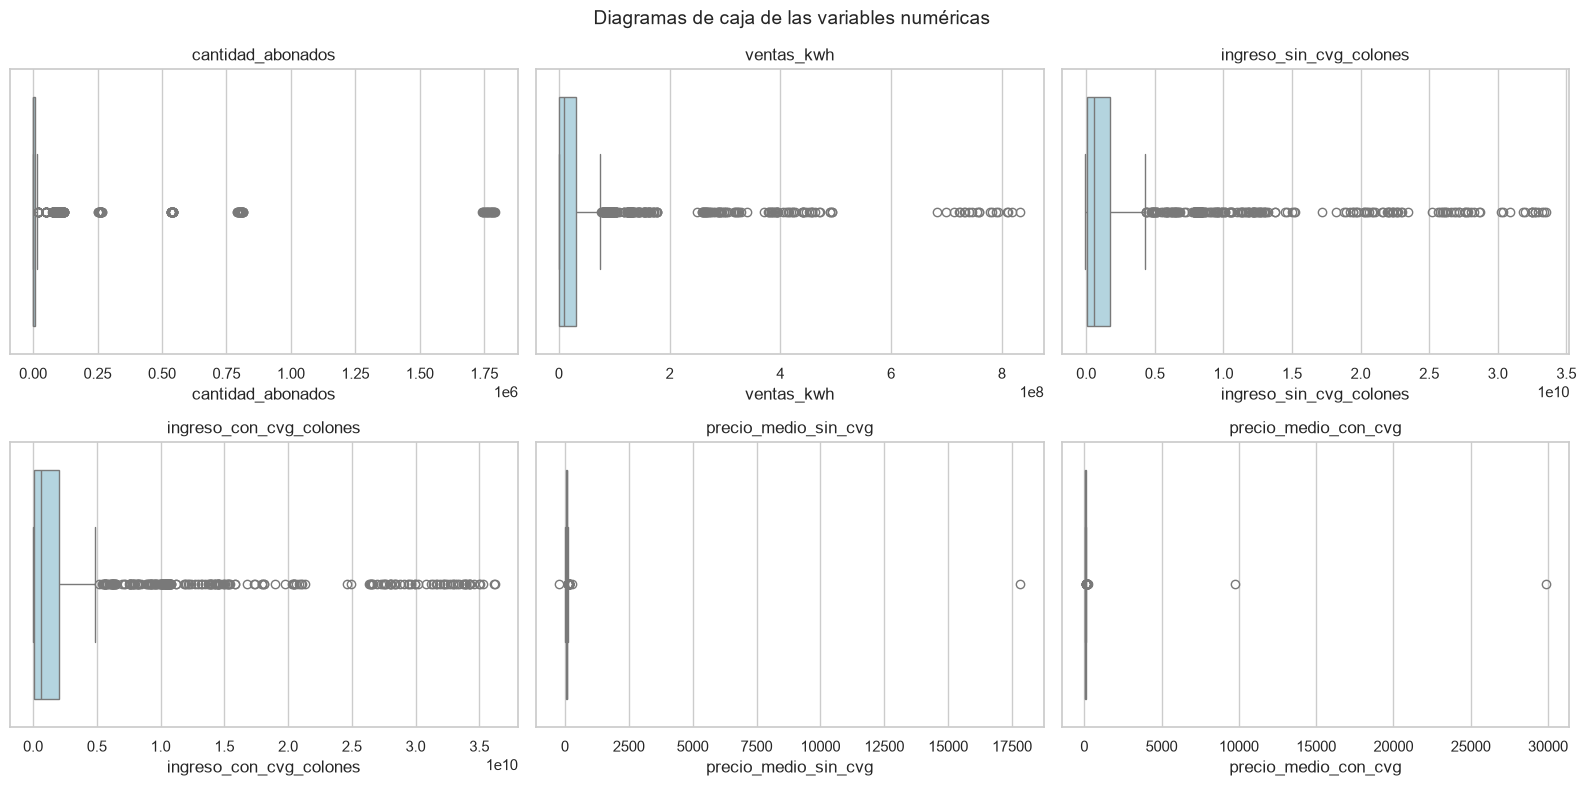

In [21]:
fig, ejes = plt.subplots(2, 3, figsize=(16, 8))
for eje, c in zip(ejes.flat, variables_continuas):
    sns.boxplot(x=df[c], ax=eje, color="lightblue")
    eje.set_title(c)
plt.suptitle("Diagramas de caja de las variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

Las cajas casi no se ven porque hay valores **millones de veces más grandes** que el resto. Hay que ver la causa con más detalle.

### 7.1 Precio medio: valores imposibles

In [22]:
# Un precio de electricidad real ronda entre 40 y 150 ₡/kWh
df.sort_values("precio_medio_sin_cvg", ascending=False)[
    ["mes", "anio", "empresa", "tarifa", "ventas_kwh", "ingreso_sin_cvg_colones", "precio_medio_sin_cvg"]
].head(10)

,mes,anio,empresa,tarifa,ventas_kwh,ingreso_sin_cvg_colones,precio_medio_sin_cvg
821,Enero,2025,COOPESANTOS,Ventas al servicio de Distribución,"1,500.00","26,744,026.64","17,829.35"
900,Agosto,2026,COOPESANTOS,Ventas al servicio de Distribución,"190,931.00","51,735,198.27",270.96
1319,Marzo,2026,COOPESANTOS,Industrial,"240,143.00","40,644,770.00",169.25
1393,Febrero,2026,COOPESANTOS,Industrial,"288,526.00","48,448,460.00",167.92
143,Noviembre,2025,COOPESANTOS,Industrial,"143,521.54","23,588,320.00",164.35
949,Agosto,2026,COOPESANTOS,Industrial,"168,636.23","27,531,450.00",163.26
1467,Enero,2026,COOPESANTOS,Industrial,"283,396.17","45,076,160.00",159.06
1097,Junio,2026,COOPESANTOS,Industrial,"172,110.22","26,579,860.00",154.44
69,Diciembre,2025,COOPESANTOS,Industrial,"185,299.12","28,405,220.00",153.29
1245,Abril,2026,COOPESANTOS,Industrial,"186,710.31","28,610,600.00",153.24


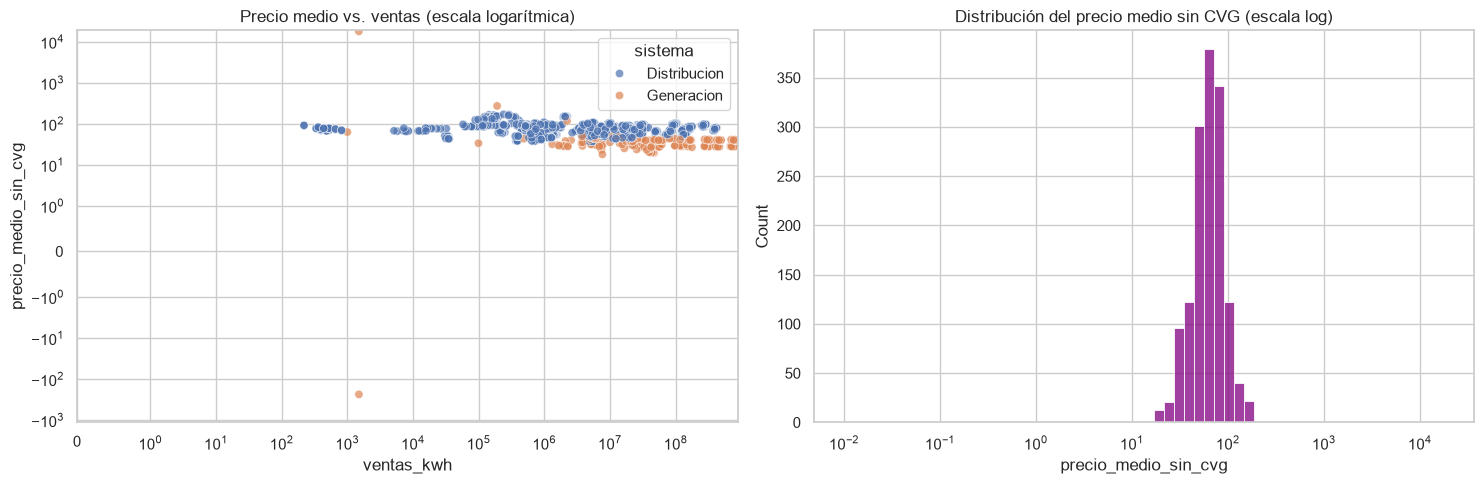

In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=df, x="ventas_kwh", y="precio_medio_sin_cvg", hue="sistema", ax=ejes[0], alpha=0.7)
ejes[0].set_xscale("symlog", linthresh=1); ejes[0].set_xlim(left=0); ejes[0].set_yscale("symlog", linthresh=1)
ejes[0].set_title("Precio medio vs. ventas (escala logarítmica)")
sns.histplot(df["precio_medio_sin_cvg"].dropna().clip(lower=0.01), log_scale=True, bins=60, ax=ejes[1], color="purple")
ejes[1].set_title("Distribución del precio medio sin CVG (escala log)")
plt.tight_layout()
plt.show()

Las 11 filas con ventas de 0 o 1 kWh ya quedaron en `NaN` en el punto 6. Aun así quedan precios fuera de lo normal: por ejemplo, COOPESANTOS en enero 2025 reporta **1 500 kWh** y un precio de casi **17 800 ₡/kWh**. Pasa lo mismo: al dividir un ingreso grande entre muy pocos kWh, el precio se dispara. Son **errores del dato**, no precios reales.

### 7.2 Ingresos negativos

In [24]:
df.loc[(df["ingreso_sin_cvg_colones"] < 0) | (df["precio_medio_sin_cvg"] < 0),
       ["mes", "anio", "empresa", "tarifa", "ventas_kwh", "ingreso_sin_cvg_colones", "precio_medio_sin_cvg"]]

,mes,anio,empresa,tarifa,ventas_kwh,ingreso_sin_cvg_colones,precio_medio_sin_cvg
808,Enero,2025,COOPEALFARORUIZ,Ventas al servicio de Distribución,"1,500.00","-355,151.54",-236.77
1345,Febrero,2026,COOPELESCA,Ventas al servicio de Distribución,NaN,"-115,904,929.23",NaN


### 7.3 Filas de TOTAL NACIONAL

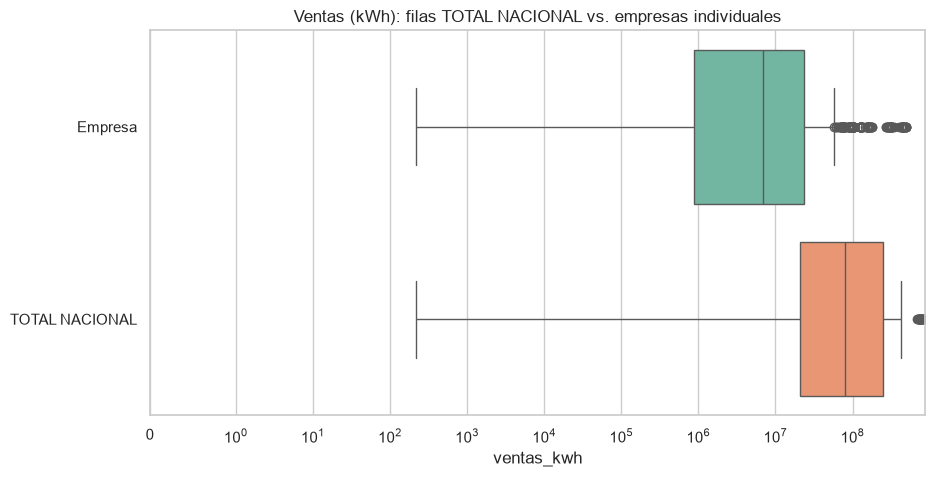

In [25]:
df["es_total_nacional"] = np.where(df["empresa"] == "TOTAL NACIONAL", "TOTAL NACIONAL", "Empresa")
sns.boxplot(data=df, x="ventas_kwh", y="es_total_nacional", hue="es_total_nacional", palette="Set2", legend=False)
plt.xscale("symlog", linthresh=1)
plt.xlim(left=0)
plt.title("Ventas (kWh): filas TOTAL NACIONAL vs. empresas individuales")
plt.ylabel("")
plt.show()
df = df.drop(columns="es_total_nacional")

### 7.4 Comparación por variable sin los valores extremos (escala log)

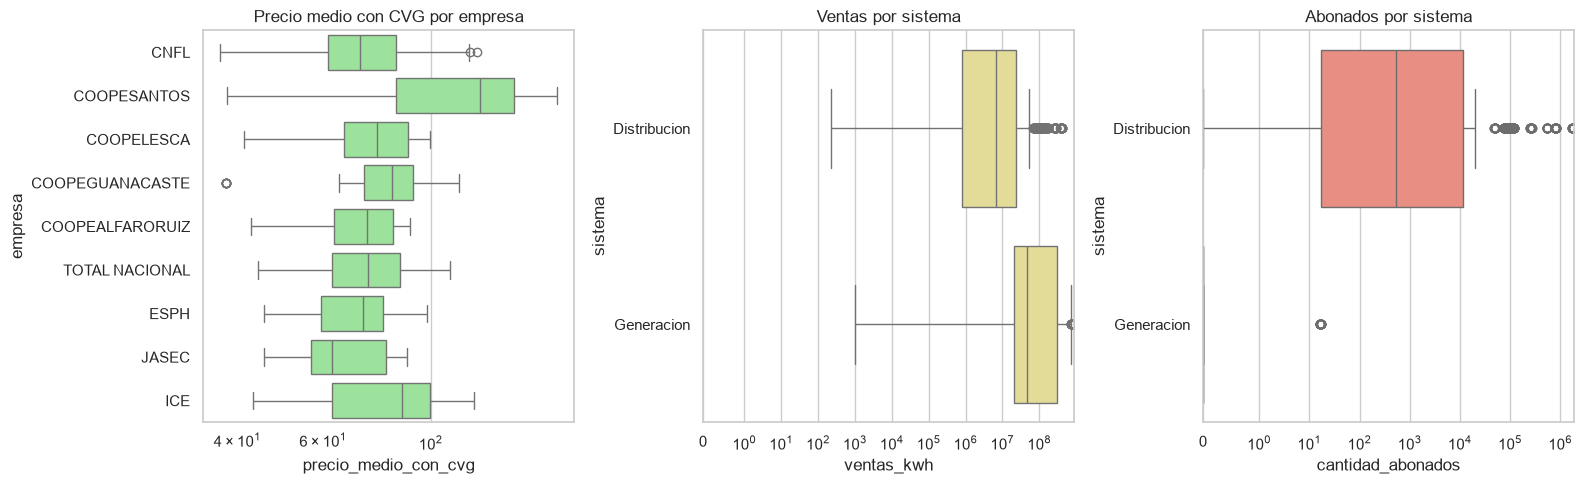

In [26]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 5))
sns.boxplot(data=df[df["sistema"] == "Distribucion"], x="precio_medio_con_cvg", y="empresa", ax=ejes[0], color="lightgreen")
ejes[0].set_xscale("log"); ejes[0].set_title("Precio medio con CVG por empresa")
sns.boxplot(data=df, x="ventas_kwh", y="sistema", ax=ejes[1], color="khaki")
ejes[1].set_xscale("symlog", linthresh=1); ejes[1].set_xlim(left=0); ejes[1].set_title("Ventas por sistema")
sns.boxplot(data=df, x="cantidad_abonados", y="sistema", ax=ejes[2], color="salmon")
ejes[2].set_xscale("symlog", linthresh=1); ejes[2].set_xlim(left=0); ejes[2].set_title("Abonados por sistema")
plt.tight_layout()
plt.show()

**Hallazgos sobre los valores atípicos:**
1. **Precios medios imposibles.** Algunos registros tienen precios de miles de ₡/kWh, cuando lo normal está entre 40 y 150. Vienen de ventas demasiado bajas para el ingreso reportado, así que son **errores** y hay que corregirlos.
2. **Ingresos y precios negativos.** Son pocos y corresponden a ajustes contables (devoluciones o liquidaciones del CVG). Para analizar precios no tienen sentido, así que también son atípicos que hay que tratar.
3. **TOTAL NACIONAL, ICE y CNFL.** Tienen ventas, ingresos y abonados mucho más altos que el resto. Estos sí son **valores reales**: son las empresas más grandes del país. Lo que no corresponde es **TOTAL NACIONAL**, porque es la suma de las demás y cuenta todo dos veces.
4. Las variables de volumen (abonados, ventas, ingresos) tienen una **asimetría positiva muy fuerte**. Eso es normal en datos de empresas de tamaños muy distintos.

**Recomendación para el punto 8:** quitar las filas de TOTAL NACIONAL; recalcular o limitar los precios medios fuera de rango; no recortar las ventas de ICE y CNFL porque son datos reales.

## Punto 9. Conversión de tipos de datos
| Columna | Tipo original | Tipo nuevo | Motivo |
|---|---|---|---|
| `mes` | texto con espacios | `category` ordenada | Limpiar espacios; los meses tienen un orden |
| `anio` | `int64` | `int16` | Solo toma los valores 2025–2026 |
| `fecha` (nueva) | — | `datetime64` | Une año y mes en una fecha real para trabajar con el tiempo |
| `empresa`, `tarifa`, `sistema` | texto | `category` | Pocos valores que se repiten (ahorra memoria) |
| `trimestre` | texto | `category` ordenada | I < II < III < IV |
| `periodo_trimestral` | texto `"2025 4"` | `Period` trimestral | Representa un trimestre real |
| `cantidad_abonados` | `int64` | `Int64` | Entero que admite nulos |
| ventas, ingresos, precios | `float64` | `float64` | Ya están bien (son decimales) |

In [27]:
tipos_antes = df.dtypes.astype(str)

meses = ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio",
         "Agosto", "Setiembre", "Octubre", "Noviembre", "Diciembre"]
df["mes"] = pd.Categorical(df["mes"].str.strip(), categories=meses, ordered=True)
df["anio"] = df["anio"].astype("int16")
df["fecha"] = pd.to_datetime(dict(year=df["anio"], month=df["mes"].cat.codes + 1, day=1))

for c in ["empresa", "tarifa", "sistema"]:
    df[c] = df[c].str.strip().astype("category")

df["trimestre"] = pd.Categorical(df["trimestre"].str.strip(),
                                 categories=["I Trimestre", "II Trimestre", "III Trimestre", "IV Trimestre"],
                                 ordered=True)
df["periodo_trimestral"] = pd.PeriodIndex(
    df["periodo_trimestral"].str.replace(" ", "Q"), freq="Q")
df["cantidad_abonados"] = df["cantidad_abonados"].astype("Int64")

pd.DataFrame({"antes": tipos_antes, "despues": df.dtypes.astype(str)}).reindex(df.columns).fillna("(columna nueva)")

,antes,despues
mes,str,category
anio,int64,int16
empresa,str,category
tarifa,str,category
cantidad_abonados,int64,Int64
ventas_kwh,float64,float64
ingreso_sin_cvg_colones,float64,float64
ingreso_con_cvg_colones,float64,float64
precio_medio_sin_cvg,float64,float64
precio_medio_con_cvg,float64,float64


In [28]:
print("Meses sin espacios:", df["mes"].cat.categories.tolist())
print("Rango de fechas:", df["fecha"].min().date(), "a", df["fecha"].max().date())
print("Memoria usada ahora: {:.1f} KB".format(df.memory_usage(deep=True).sum() / 1024))
df.info()

Meses sin espacios: ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Setiembre', 'Octubre', 'Noviembre', 'Diciembre']
Rango de fechas: 2025-01-01 a 2026-08-01
Memoria usada ahora: 106.7 KB
<class 'pandas.DataFrame'>
RangeIndex: 1472 entries, 0 to 1471
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   mes                      1472 non-null   category      
 1   anio                     1472 non-null   int16         
 2   empresa                  1472 non-null   category      
 3   tarifa                   1472 non-null   category      
 4   cantidad_abonados        1472 non-null   Int64         
 5   ventas_kwh               1461 non-null   float64       
 6   ingreso_sin_cvg_colones  1472 non-null   float64       
 7   ingreso_con_cvg_colones  1472 non-null   float64       
 8   precio_medio_sin_cvg     1461 non-null   float64       
 9   precio_medio

**Para el punto 8:** `df` queda con los nombres en español, los nulos ocultos marcados como `NaN` (11 filas), los valores atípicos identificados y los tipos de datos corregidos. Se sigue trabajando sobre **el mismo `df`**; no hay que volver a cargar el archivo.

# Parte 3 (puntos 8, 10 y 11)

## Punto 8. Imputación de nulos y tratamiento de atípicos

- **Total nacional.** Se eliminan las filas de `TOTAL NACIONAL` porque ya agregan los datos de las empresas. Incluirlas contaría dos veces esos valores.
- **Ventas faltantes.** Se usa la mediana de la misma empresa y tarifa. Si el grupo carece de ventas válidas, se usa la mediana de esa tarifa. La mediana depende de la posición central de los datos y resiste mejor los valores extremos que el promedio. Después se recalculan ambos precios medios dividiendo el ingreso correspondiente entre las ventas.
- **Precios fuera de rango.** Se marcan como faltantes los precios negativos o superiores a 300 ₡/kWh. Se imputan con las medianas de los precios válidos, primero por empresa y tarifa y luego por tarifa. Los valores altos de ventas, ingresos y abonados de ICE y CNFL se conservan en esta limpieza porque reflejan el tamaño de las empresas.

In [29]:
def eliminar_total_nacional(df):
    """Elimina las filas agregadas y retira la categoría TOTAL NACIONAL."""
    df = df.loc[df["empresa"] != "TOTAL NACIONAL"].copy()
    df["empresa"] = df["empresa"].cat.remove_unused_categories()
    return df


def rellenar_con_mediana(df, columna):
    """Rellena con la mediana por empresa y tarifa o, en su defecto, por tarifa."""
    mediana_grupo = df.groupby(["empresa", "tarifa"], observed=True)[columna].transform("median")
    mediana_tarifa = df.groupby("tarifa", observed=True)[columna].transform("median")
    return df[columna].fillna(mediana_grupo).fillna(mediana_tarifa)


def imputar_nulos(df):
    """Imputa las ventas faltantes y recalcula los dos precios medios."""
    df["ventas_kwh"] = rellenar_con_mediana(df, "ventas_kwh")
    df["precio_medio_sin_cvg"] = df["ingreso_sin_cvg_colones"] / df["ventas_kwh"]
    df["precio_medio_con_cvg"] = df["ingreso_con_cvg_colones"] / df["ventas_kwh"]
    return df


def tratar_atipicos(df):
    """Reemplaza los precios fuera del intervalo [0, 300] ₡/kWh."""
    for columna in ["precio_medio_sin_cvg", "precio_medio_con_cvg"]:
        df[columna] = df[columna].where(df[columna].between(0, 300))
        df[columna] = rellenar_con_mediana(df, columna)
    return df

In [30]:
df = eliminar_total_nacional(df)
precio_con_cvg_antes = df["precio_medio_con_cvg"].copy()

df = imputar_nulos(df)
df = tratar_atipicos(df)

df.isnull().sum()

mes                        0
anio                       0
empresa                    0
tarifa                     0
cantidad_abonados          0
ventas_kwh                 0
ingreso_sin_cvg_colones    0
ingreso_con_cvg_colones    0
precio_medio_sin_cvg       0
precio_medio_con_cvg       0
trimestre                  0
sistema                    0
periodo_trimestral         0
fecha                      0
dtype: int64

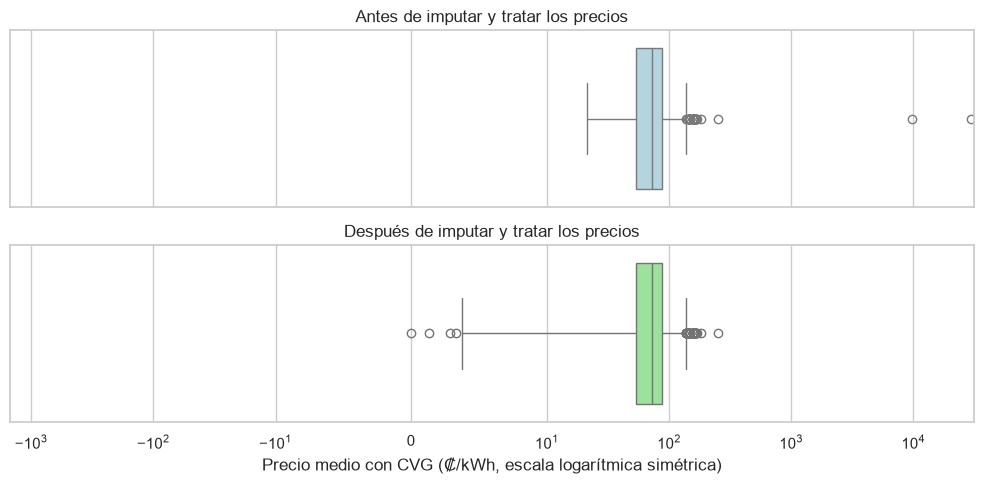

In [31]:
fig, ejes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
sns.boxplot(x=precio_con_cvg_antes.dropna(), ax=ejes[0], color="lightblue")
sns.boxplot(x=df["precio_medio_con_cvg"], ax=ejes[1], color="lightgreen")

ejes[0].set_title("Antes de imputar y tratar los precios")
ejes[0].set_xlabel("")
ejes[1].set_title("Después de imputar y tratar los precios")
ejes[1].set_xscale("symlog", linthresh=10)
ejes[1].set_xlabel("Precio medio con CVG (₡/kWh, escala logarítmica simétrica)")
fig.tight_layout()
plt.show()

## Punto 10. Conversión de categorías a variables numéricas

Se codifica `sistema` como 0 para Distribución y 1 para Generación. Los códigos de `mes` y `trimestre` empiezan en 1 y conservan el orden del calendario. Para `empresa` y `tarifa`, se crea un indicador binario por categoría porque son variables sin orden natural.

Se quitan `periodo_trimestral` y `fecha` porque el modelo recibe la información del calendario mediante `anio`, `mes` y `trimestre`.

In [32]:
df["sistema"] = df["sistema"].map({"Distribucion": 0, "Generacion": 1}).astype(int)
df["mes"] = df["mes"].cat.codes + 1
df["trimestre"] = df["trimestre"].cat.codes + 1

df = df.drop(columns=["periodo_trimestral", "fecha"])
df = pd.get_dummies(df, columns=["empresa", "tarifa"], dtype=int)

df.dtypes

mes                                                int8
anio                                              int16
cantidad_abonados                                 Int64
ventas_kwh                                      float64
ingreso_sin_cvg_colones                         float64
ingreso_con_cvg_colones                         float64
precio_medio_sin_cvg                            float64
precio_medio_con_cvg                            float64
trimestre                                          int8
sistema                                           int64
empresa_CNFL                                      int64
empresa_COOPEALFARORUIZ                           int64
empresa_COOPEGUANACASTE                           int64
empresa_COOPELESCA                                int64
empresa_COOPESANTOS                               int64
empresa_ESPH                                      int64
empresa_ICE                                       int64
empresa_JASEC                                   

## Punto 11. Estandarización de variables continuas

`StandardScaler` resta la media y divide por la desviación estándar poblacional de los abonados, las ventas, los ingresos y el precio medio sin CVG. Con MinMax, los máximos muy altos en ventas e ingresos concentrarían gran parte de los valores cerca de 0. La estandarización expresa cada observación en desviaciones respecto a su media.

El precio medio con CVG conserva sus unidades (₡/kWh) para usarlo como variable dependiente. El año y las categorías codificadas conservan sus valores numéricos.

In [33]:
from sklearn.preprocessing import StandardScaler

columnas_a_escalar = [columna for columna in variables_continuas if columna != "precio_medio_con_cvg"]
resumen_antes = df[variables_continuas].describe().T

escalador = StandardScaler()
df[columnas_a_escalar] = escalador.fit_transform(df[columnas_a_escalar])
resumen_despues = df[variables_continuas].describe().T

display(pd.concat({"Antes": resumen_antes, "Después": resumen_despues}, names=["Etapa"]))

valores_escalados = df[columnas_a_escalar]
display(pd.DataFrame({
    "Media": valores_escalados.mean(),
    "Desviación estándar poblacional": valores_escalados.std(ddof=0),
}).round(6))

count             mean              std  \
Etapa                                                                        
Antes   cantidad_abonados       1,236.00        33,297.56       122,353.80   
        ventas_kwh              1,236.00    30,698,238.17    72,530,033.78   
        ingreso_sin_cvg_colones 1,236.00 1,635,925,507.87 3,207,228,623.80   
        ingreso_con_cvg_colones 1,236.00 1,926,981,350.51 3,850,691,327.26   
        precio_medio_sin_cvg    1,236.00            66.80            27.38   
        precio_medio_con_cvg    1,236.00            73.85            28.03   
Después cantidad_abonados       1,236.00            -0.00             1.00   
        ventas_kwh              1,236.00            -0.00             1.00   
        ingreso_sin_cvg_colones 1,236.00            -0.00             1.00   
        ingreso_con_cvg_colones 1,236.00            -0.00             1.00   
        precio_medio_sin_cvg    1,236.00            -0.00             1.00   
        precio_medio_con_cvg    1,236.00            73.85            28.03   

                                            min           25%            50%  \
Etapa                                                                          
Antes   cantidad_abonados                  0.00          0.00         207.00   
        ventas_kwh                       218.77    883,928.56   6,840,897.00   
        ingreso_sin_cvg_colones -115,904,929.23 54,755,466.41 435,707,850.00   
        ingreso_con_cvg_colones           45.02 58,759,631.20 474,292,050.00   
        precio_medio_sin_cvg               1.40         49.26          64.68   
        precio_medio_con_cvg               0.00         53.81          71.95   
Después cantidad_abonados                 -0.27         -0.27          -0.27   
        ventas_kwh                        -0.42         -0.41          -0.33   
        ingreso_sin_cvg_colones           -0.55         -0.49          -0.37   
        ingreso_con_cvg_colones           -0.50         -0.49          -0.38   
        precio_medio_sin_cvg              -2.39         -0.64          -0.08   
        precio_medio_con_cvg               0.00         53.81          71.95   

                                             75%               max  
Etapa                                                               
Antes   cantidad_abonados               6,290.00        814,350.00  
        ventas_kwh                 23,462,287.75    493,515,933.97  
        ingreso_sin_cvg_colones 1,445,698,951.50 19,657,965,084.88  
        ingreso_con_cvg_colones 1,616,376,500.00 21,295,216,472.62  
        precio_medio_sin_cvg               82.30            270.96  
        precio_medio_con_cvg               87.40            249.50  
Después cantidad_abonados                  -0.22              6.39  
        ventas_kwh                         -0.10              6.38  
        ingreso_sin_cvg_colones            -0.06              5.62  
        ingreso_con_cvg_colones            -0.08              5.03  
        precio_medio_sin_cvg                0.57              7.46  
        precio_medio_con_cvg               87.40            249.50

,Media,Desviación estándar poblacional
cantidad_abonados,-0.00,1.00
ventas_kwh,-0.00,1.00
ingreso_sin_cvg_colones,-0.00,1.00
ingreso_con_cvg_colones,-0.00,1.00
precio_medio_sin_cvg,-0.00,1.00
